Домашнее задание
Как узнать свою аудиторию? Построение различных вариантов кластеризаций и интерпретация результатов.

Цель:
понять как решать задачу сегментации клиентов.
понять, на какие группы делится аудитория и чем она характеризуется.


Описание/Пошаговая инструкция выполнения домашнего задания:
Часть 1. EDA и Preprocessing.

Скачайте данные по клиентам немецкого банка: https://www.kaggle.com/uciml/german-credit;
Проведите EDA, чтобы познакомиться с признаками;
Преобразуйте все признаки в числовые подходящими методами;
Приведите все данные к одному масштабу (а заодно поясните, почему это необходимая операция при кластеризации).

Часть 2. Моделирование.

Постройте три варианта кластеризации: k-means, hierarhical и DBSCAN, подберите оптимальное количество кластеров для каждого метода при помощи Elbow method и Silhouette plot;
Также воспользуйтесь различными вариантами сжатия признакового пространства (PCA, UMAP, tSNE) и визуализируйте результаты кластеризации на двумерной плоскости.

Часть 3. Интерпретация.

Теперь ваша задача - попытаться проинтерпретировать получившиеся кластеры, начните с простого расчета средних значений признаков для каждого из кластеров, есть ли интересные закономерности?
Теперь постройте boxplot-ы для каждого признака, сгруппировав значения по кластерам, по каким признакам заметно наибольшее отличие кластеров друг от друга? Можно ли их интерпретировать?

Критерии оценки:
EDA и Preprocessing - 2 балла.
Моделирование - 5 баллов.
Интерпретация - 3 балла.

In [2]:
# =====================
# 1. CSV load and setup configs
# =====================

import os
import time
import warnings

import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import umap

warnings.filterwarnings('ignore')

RANDOM_STATE = 555
pd.set_option('display.max_columns', None)

input_dir = 'csv_input'
output_dir = 'csv_output'
os.makedirs(output_dir, exist_ok=True)

file_path = os.path.join(input_dir, 'german_credit_data.csv')

all_cols = pd.read_csv(file_path, nrows=0).columns.tolist()
exclude_cols = ['Unnamed: 0']  # remove column with ids
use_cols = [col for col in all_cols if col not in exclude_cols]

df_raw = pd.read_csv(file_path, usecols=use_cols)

print('Shape:', df_raw.shape)
df_raw.head()

Shape: (1000, 9)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [3]:
#--------------------
# 2. EDA
#--------------------

print(df_raw.describe(include='all').round(2).to_string())
print('\nNo values in column:')
print(df_raw.isna().sum().to_string())
print('\nDuplicates:', int(df_raw.duplicated().sum()))


            Age   Sex      Job Housing Saving accounts Checking account  Credit amount  Duration Purpose
count   1000.00  1000  1000.00    1000             817              606        1000.00   1000.00    1000
unique      NaN     2      NaN       3               4                3            NaN       NaN       8
top         NaN  male      NaN     own          little           little            NaN       NaN     car
freq        NaN   690      NaN     713             603              274            NaN       NaN     337
mean      35.55   NaN     1.90     NaN             NaN              NaN        3271.26     20.90     NaN
std       11.38   NaN     0.65     NaN             NaN              NaN        2822.74     12.06     NaN
min       19.00   NaN     0.00     NaN             NaN              NaN         250.00      4.00     NaN
25%       27.00   NaN     2.00     NaN             NaN              NaN        1365.50     12.00     NaN
50%       33.00   NaN     2.00     NaN             NaN 

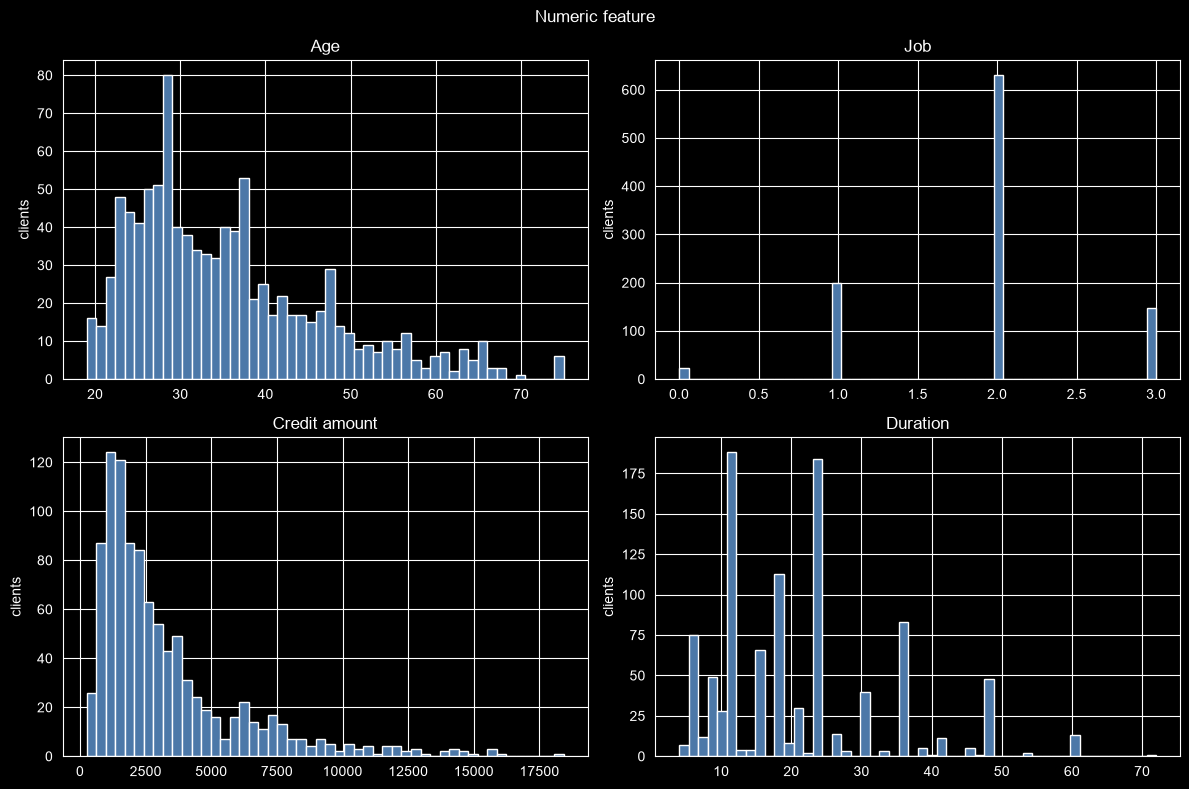

In [4]:
numeric_features = ['Age', 'Job', 'Credit amount', 'Duration']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, numeric_features):
    ax.hist(df_raw[col], bins=50, color='#4C78A8', edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('clients')
fig.suptitle('Numeric feature')
fig.tight_layout()
plt.show()

string_features = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

# replace NAN with 'unknown'. group client by categories
for col in string_features:
    counts = df_raw[col].fillna('unknown').value_counts().reset_index()
    counts.columns = [col, 'clients']
    top = np.ceil(counts['clients'].max() * 1.1)
    fig = px.bar(counts, x=col, y='clients', title=f'Clients by feature {col}', width=600, height=400)
    fig.update_yaxes(range=[0, top])
    fig.show()

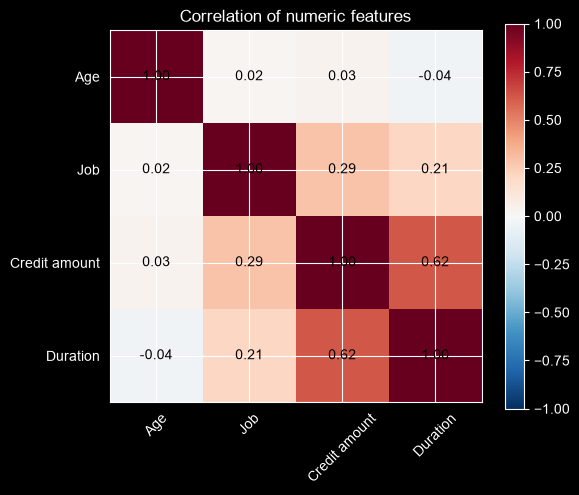

In [5]:
corr = df_raw[numeric_features].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color='black')
fig.colorbar(im, ax=ax)
ax.set_title('Correlation of numeric features')
plt.show()


In [6]:
# most correlated credit amount and duration (months)
# marked by Housing column
fig = px.scatter(df_raw, x='Duration', y='Credit amount', color='Housing', opacity=0.5,
                 title='Credit amount and duration values', width=800, height=600)
fig.show()

# marked by Sex column
fig = px.scatter(df_raw, x='Duration', y='Credit amount', color='Sex', opacity=0.5,
                 title='Credit amount and duration values', width=800, height=600)
fig.show()

# marked by Purpose column
fig = px.scatter(df_raw, x='Duration', y='Credit amount', color='Purpose', opacity=0.5,
                 title='Credit amount and duration values', width=800, height=600)
fig.show()

In [11]:
# marked by Housing and Sex looks informative, and not informative by other columns

#--------------------
# 3. Feature encoding
#--------------------

# Ordinal maps keep the original natural order of account size categories.
saving_map = {'unknown': 0, 'little': 1, 'moderate': 2, 'quite rich': 3, 'rich': 4}
checking_map = {'unknown': 0, 'little': 1, 'moderate': 2, 'rich': 3}

df_encoded = df_raw.copy()
df_encoded['Saving accounts'] = df_encoded['Saving accounts'].fillna('unknown')
df_encoded['Checking account'] = df_encoded['Checking account'].fillna('unknown')

df_encoded['Saving accounts (ord)'] = df_encoded['Saving accounts'].map(saving_map)
df_encoded['Checking account (ord)'] = df_encoded['Checking account'].map(checking_map)
df_encoded['Sex (bin)'] = (df_encoded['Sex'] == 'male').astype(int)

# Значения в столбце про размер кредита имеют длинный правый хвост и большой диапазон самих значений. если считать расстояния как эвклидово, получится искаженная картина. А основная масса значений кучкуется в левой части. Нампаевый лог(1+х) делает значимыми маленькие значения и позволяет привести к значениям типа во сколько раз расстояние до той точки больше чем расстояние до этой точки. получается нормализация как бы самой формы распределения. Отдельно скейлер оебспечивает нормализацию по значениям.
df_encoded['Credit amount (log)'] = np.log1p(df_encoded['Credit amount'])

# features without a natural order -> OHE
df_dummies = pd.get_dummies(df_encoded[['Housing', 'Purpose']], prefix_sep='_', dtype=int)

num_cols = ['Age', 'Job', 'Credit amount (log)', 'Duration',
            'Saving accounts (ord)', 'Checking account (ord)', 'Sex (bin)']
df_features = pd.concat([df_encoded[num_cols], df_dummies], axis=1)

print('Encoded features:', df_features.shape)
df_features.head()

Encoded features: (1000, 18)


,Age,Job,Credit amount (log),Duration,Saving accounts (ord),Checking account (ord),Sex (bin),Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,2,7.064759,6,0,1,1,0,1,0,0,0,0,0,0,1,0,0
1,22,2,8.691483,48,1,2,0,0,1,0,0,0,0,0,0,1,0,0
2,49,1,7.648263,12,1,0,1,0,1,0,0,0,0,1,0,0,0,0
3,45,2,8.972464,42,1,1,1,1,0,0,0,0,0,0,1,0,0,0
4,53,2,8.491055,24,1,1,1,1,0,0,0,1,0,0,0,0,0,0


In [13]:
#--------------------
# 4. Feature scaling
#--------------------

# scaler is fit on the whole dataset at once, because there is no train/test split
print('Std before scaling:')
print(df_features.std().round(2).to_string())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features)
df_scaled = pd.DataFrame(X_scaled, columns=df_features.columns)

print()
print('Std after scaling:')
print(df_scaled.std().round(4).to_string())

Std before scaling:
Age                            11.38
Job                             0.65
Credit amount (log)             0.78
Duration                       12.06
Saving accounts (ord)           0.97
Checking account (ord)          0.96
Sex (bin)                       0.46
Housing_free                    0.31
Housing_own                     0.45
Housing_rent                    0.38
Purpose_business                0.30
Purpose_car                     0.47
Purpose_domestic appliances     0.11
Purpose_education               0.24
Purpose_furniture/equipment     0.39
Purpose_radio/TV                0.45
Purpose_repairs                 0.15
Purpose_vacation/others         0.11

Std after scaling:
Age                            1.0005
Job                            1.0005
Credit amount (log)            1.0005
Duration                       1.0005
Saving accounts (ord)          1.0005
Checking account (ord)         1.0005
Sex (bin)                      1.0005
Housing_free                

In [16]:
#--------------------
# 5. KMeans: elbow method and silhouette
#--------------------

k_range = range(2, 11)
kmeans_sweep = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    kmeans_sweep.append({'k': k, 'inertia': km.inertia_,
                         'silhouette': silhouette_score(X_scaled, km.labels_)})

df_kmeans_sweep = pd.DataFrame(kmeans_sweep)
print(df_kmeans_sweep.round(4).to_string(index=False))

fig = px.line(df_kmeans_sweep, x='k', y='inertia', markers=True, # inertia as sum of squared distances from every point to assigned cluster center
              title='KMeans elbow method: inertia vs k', width=800, height=400) # how tight the clusters are around their cluster centroids
# curve becomes flat after k = 3. means from this point of view the optimal cluster number = 3

fig.show()

fig = px.line(df_kmeans_sweep, x='k', y='silhouette', markers=True,
              title='KMeans: mean silhouette vs k', width=800, height=400)
# best silhouette values are at plateau between k=3 and 4
fig.update_yaxes(range=[0, 0.3])
fig.show()

 k    inertia  silhouette
 2 16078.4481      0.1689
 3 14676.6432      0.1855
 4 13711.1908      0.1853
 5 12660.5196      0.1569
 6 11675.7797      0.1729
 7 10735.6306      0.1863
 8  9779.6749      0.2138
 9  8798.5455      0.2324
10  7927.7091      0.2575


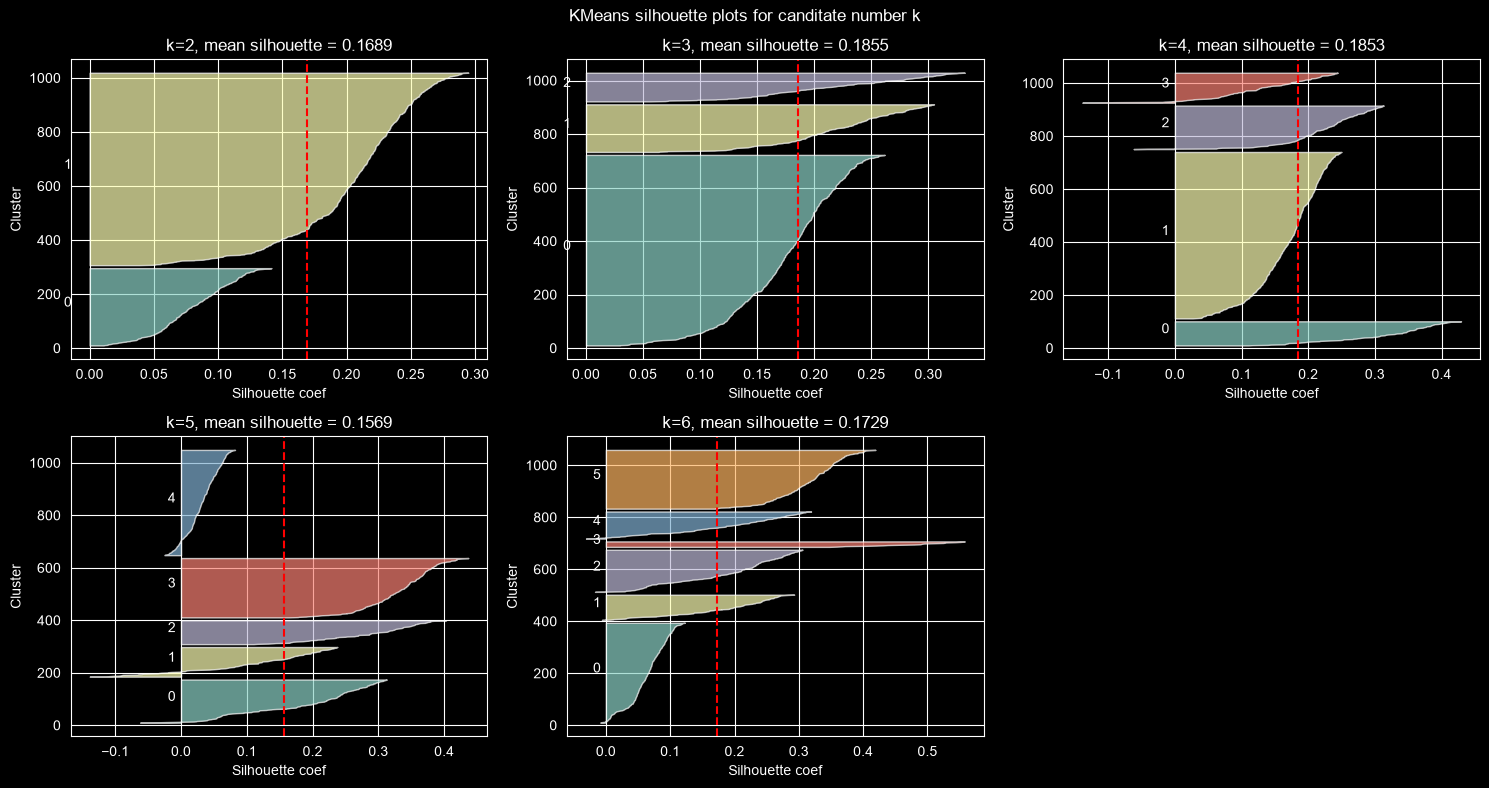


KMeans cluster sizes: [713, 179, 108]


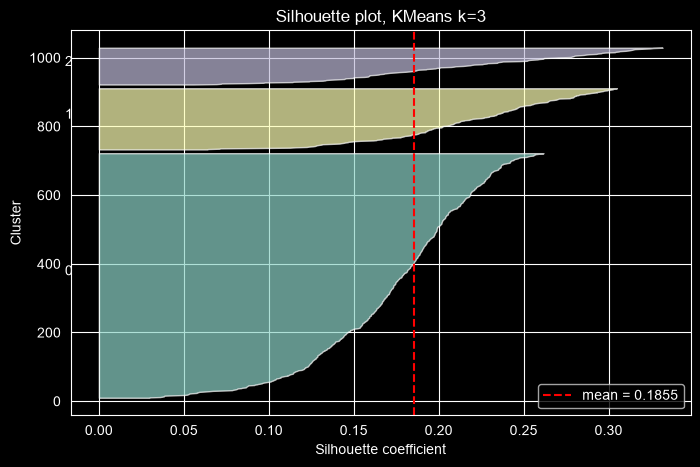

In [20]:
# We choose k=3 based on measures
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, k in zip(axes.flat, [2, 3, 4, 5, 6]):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled) # set n_init>4 to make sure random start values to cluster dont be unlucky
    sil_k = silhouette_samples(X_scaled, km.labels_)
    y_lower = 10
    for cluster in range(k):
        cluster_sil = np.sort(sil_k[km.labels_ == cluster])
        y_upper = y_lower + len(cluster_sil)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil, alpha=0.7)
        ax.text(-0.02, (y_lower + y_upper) / 2, str(cluster))
        y_lower = y_upper + 10
    ax.axvline(sil_k.mean(), color='red', linestyle='--')
    ax.set_title(f'k={k}, mean silhouette = {sil_k.mean():.4f}')
    ax.set_xlabel('Silhouette coef')
    ax.set_ylabel('Cluster')
axes.flat[5].axis('off')
fig.suptitle('KMeans silhouette plots for canditate number k')
fig.tight_layout()
plt.show()

KM_K = 3

km_final = KMeans(n_clusters=KM_K, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
labels_km = km_final.labels_
print('\nKMeans cluster sizes:', np.bincount(labels_km).tolist())

# Silhouette plot for chosen k
sil_values = silhouette_samples(X_scaled, labels_km)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for cluster in sorted(set(labels_km)):
    cluster_sil = np.sort(sil_values[labels_km == cluster])
    y_upper = y_lower + len(cluster_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil, alpha=0.7)
    ax.text(-0.02, (y_lower + y_upper) / 2, str(cluster))
    y_lower = y_upper + 10
ax.axvline(sil_values.mean(), color='red', linestyle='--', label=f'mean = {sil_values.mean():.4f}')
ax.set_xlabel('Silhouette coefficient')
ax.set_ylabel('Cluster')
ax.set_title(f'Silhouette plot, KMeans k={KM_K}')
ax.legend()
plt.show()

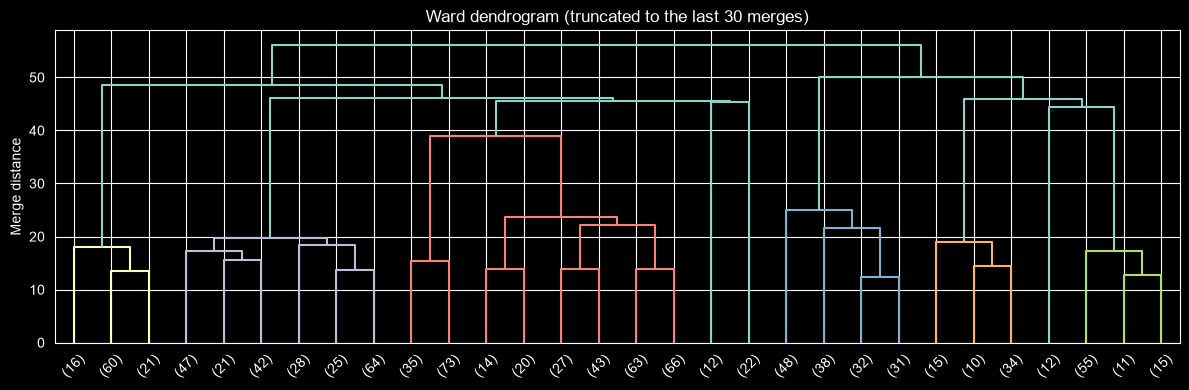

k=2: cut distance 56.04, jump from k+1: 6.02
k=3: cut distance 50.02, jump from k+1: 1.41
k=4: cut distance 48.61, jump from k+1: 2.45
k=5: cut distance 46.16, jump from k+1: 0.19
k=6: cut distance 45.96, jump from k+1: 0.38
k=7: cut distance 45.59, jump from k+1: 0.29

Silhouette by linkage and k:
linkage  average  complete    ward
k                                 
2         0.4863    0.4863  0.1554
3         0.4811    0.4811  0.1454
4         0.3846    0.3846  0.1725
5         0.2534    0.1967  0.1528
6         0.2039    0.2221  0.1795
7         0.2003    0.1497  0.1943
8         0.1940    0.1433  0.2085
9         0.1603    0.1700  0.2245
10        0.1536    0.1657  0.2475



In [21]:
#--------------------
# 6. Hierarchical clustering
#--------------------

link_matrix = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(link_matrix, truncate_mode='lastp', p=30, ax=ax)
ax.set_title('Ward dendrogram (truncated to the last 30 merges)')
ax.set_ylabel('Merge distance')
plt.tight_layout()
plt.show()

# Merge-distance analysis: the cut height for k clusters and its jump from k+1
merge_dist = link_matrix[:, 2]
n_points = len(X_scaled)
for k in range(2, 8):
    cut = merge_dist[n_points - k]
    prev = merge_dist[n_points - k - 1]
    print(f'k={k}: cut distance {cut:.2f}, jump from k+1: {cut - prev:.2f}')
print()

hc_sweep = []
for method in ['ward', 'complete', 'average']:
    for k in k_range:
        hc = AgglomerativeClustering(n_clusters=k, linkage=method).fit(X_scaled)
        hc_sweep.append({'linkage': method, 'k': k,
                         'silhouette': silhouette_score(X_scaled, hc.labels_)})
df_hc_sweep = pd.DataFrame(hc_sweep)
print('Silhouette by linkage and k:')
print(df_hc_sweep.pivot(index='k', columns='linkage', values='silhouette').round(4).to_string())
print()
# Complete and average linkages gave us incorrect clusters (the methods just not suitable)
# Ward focuses on group merge where variance growth still minimal -> it gives balanced clusters

In [22]:
# Largest merge supports k=2, next merge 0.1454 supports k=4 with balanced sizes, so we try k=4
HC_K = 4

hc_final = AgglomerativeClustering(n_clusters=HC_K, linkage='ward').fit(X_scaled)
labels_hc = hc_final.labels_
print('Ward cluster sizes:', np.bincount(labels_hc).tolist())
print('Ward silhouette:', round(silhouette_score(X_scaled, labels_hc), 4))

Ward cluster sizes: [602, 152, 149, 97]
Ward silhouette: 0.1725


In [23]:
#--------------------
# 7. DBSCAN
#--------------------

# DBSCAN takes eps and number of samples instead of the number of clusters.
# eps candidates come from k-distance curve -
# distance to the min_samples-th nearest neighbor, based on quantiles.
dbscan_grid = []
for ms in [3, 5, 8, 10]:
    nn = NearestNeighbors(n_neighbors=ms).fit(X_scaled)
    dist, _ = nn.kneighbors(X_scaled)
    sorted_dist = np.sort(dist[:, -1])
    for q in [0.90, 0.95, 0.97, 0.99]:
        eps = float(sorted_dist[int(q * len(sorted_dist)) - 1])
        db = DBSCAN(eps=eps, min_samples=ms).fit(X_scaled)
        labels = db.labels_
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = float((labels == -1).mean())
        mask = labels != -1
        sil = silhouette_score(X_scaled[mask], labels[mask]) if n_clusters >= 2 else np.nan
        dbscan_grid.append({'min_samples': ms, 'k_dist_quantile': q, 'eps': round(eps, 4),
                            'n_clusters': n_clusters, 'noise_share': round(noise_share, 4),
                            'silhouette': round(sil, 4)})

df_dbscan_grid = pd.DataFrame(dbscan_grid)
print(df_dbscan_grid.sort_values('silhouette', ascending=False).to_string(index=False))
print()
# Small eps (quantiles 0.90..0.95) cut the single dense cloud into 10-18 cluster, which is not good and no clear borders
# minimum noise amount reached at min_samples=10 and the 0.99 quantile
# we take that config.

 min_samples  k_dist_quantile    eps  n_clusters  noise_share  silhouette
           8             0.99 4.8927           4        0.001      0.3847
          10             0.99 5.5115           4        0.000      0.3846
           3             0.90 2.6701          18        0.067      0.2962
           8             0.97 4.3474           5        0.007      0.2533
           5             0.99 4.4152           5        0.004      0.2532
           3             0.99 4.0761           5        0.006      0.2531
          10             0.97 4.5608           4        0.013      0.2497
          10             0.95 4.2281           4        0.017      0.2493
           3             0.95 3.0763          16        0.035      0.2425
           5             0.90 3.0821          16        0.043      0.2418
           3             0.97 3.3954          13        0.017      0.2256
           8             0.90 3.5047           6        0.050      0.2156
          10             0.90 3.6649  

In [25]:
DB_MIN_SAMPLES = 10
DB_EPS = float(df_dbscan_grid[(df_dbscan_grid['min_samples'] == DB_MIN_SAMPLES)
                              & (df_dbscan_grid['k_dist_quantile'] == 0.99)]['eps'].item())
print('Selected DBSCAN parameters: eps =', DB_EPS, ', min_samples =', DB_MIN_SAMPLES)

# k-distance curve for selected min_samples with eps marked
nn = NearestNeighbors(n_neighbors=DB_MIN_SAMPLES).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
k_dist_sorted = np.sort(dist[:, -1])

fig = px.line(x=range(len(k_dist_sorted)), y=k_dist_sorted,
              title=f'{DB_MIN_SAMPLES}-NN distance curve',
              labels={'x': 'clients sorted by k-distance', 'y': 'k-distance'},
              width=800, height=500)
fig.add_hline(y=DB_EPS, line_dash='dash', annotation_text=f'eps = {DB_EPS:.4f}')
fig.show()

db_final = DBSCAN(eps=DB_EPS, min_samples=DB_MIN_SAMPLES).fit(X_scaled)
labels_db = db_final.labels_
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
noise_share_db = float((labels_db == -1).mean())
mask = labels_db != -1
sil_db = silhouette_score(X_scaled[mask], labels_db[mask])

print('DBSCAN clusters:', n_clusters_db, '| noise share:', round(noise_share_db, 4))
print('DBSCAN silhouette (non-noise points):', round(sil_db, 4))
print('DBSCAN cluster sizes (noise would be -1):')
print(pd.Series(labels_db).value_counts().sort_index().to_string())

Selected DBSCAN parameters: eps = 5.5115 , min_samples = 10


DBSCAN clusters: 4 | noise share: 0.0
DBSCAN silhouette (non-noise points): 0.3846
DBSCAN cluster sizes (noise would be -1):
0    954
1     12
2     22
3     12


PCA explained variance ratio: [0.1246 0.1077] | total: 0.2322
UMAP fitted in 12.8s


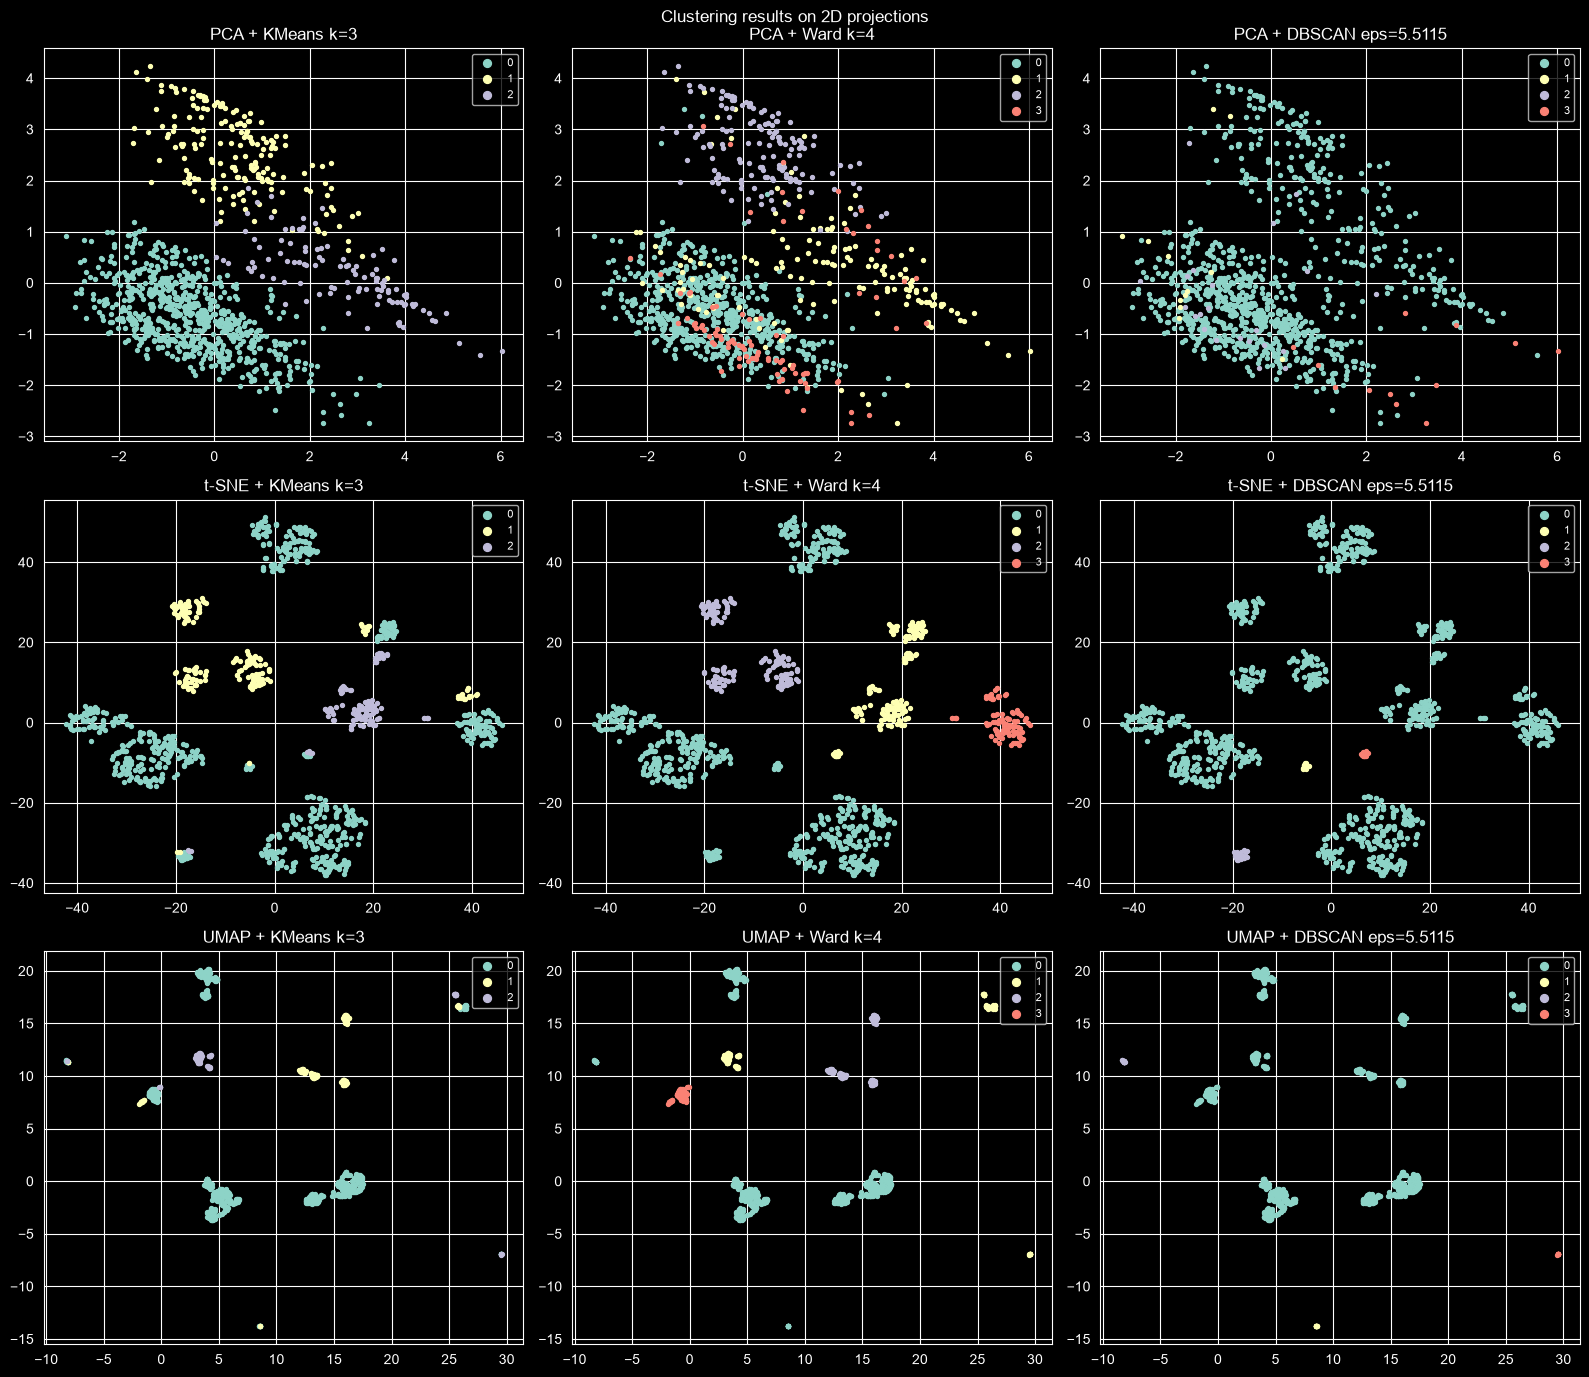

In [26]:
#--------------------
# 8. Feature space compression: PCA, t-SNE, UMAP
#--------------------

# 18 dimension SPACE compression to 2D with methods ^

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X_scaled)
print('PCA explained variance ratio:', np.round(pca_2d.explained_variance_ratio_, 4),
      '| total:', round(float(pca_2d.explained_variance_ratio_.sum()), 4))

X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE,
              init='pca').fit_transform(X_scaled)

t0 = time.time()
X_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                   random_state=RANDOM_STATE).fit_transform(X_scaled)
print(f'UMAP fitted in {time.time() - t0:.1f}s')

label_sets = {f'KMeans k={KM_K}': labels_km,
              f'Ward k={HC_K}': labels_hc,
              f'DBSCAN eps={DB_EPS:.4f}': labels_db}
projections = {'PCA': X_pca, 't-SNE': X_tsne, 'UMAP': X_umap}

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for row, (proj_name, coords) in enumerate(projections.items()):
    for col, (label_name, labels) in enumerate(label_sets.items()):
        ax = axes[row, col]
        for cluster in sorted(set(labels)):
            mask = labels == cluster
            if cluster == -1:
                ax.scatter(coords[mask, 0], coords[mask, 1], s=8, c='lightgray', label='noise')
            else:
                ax.scatter(coords[mask, 0], coords[mask, 1], s=8, label=str(cluster))
        ax.set_title(f'{proj_name} + {label_name}')
        ax.legend(markerscale=2, fontsize=8)
fig.suptitle('Clustering results on 2D projections')
fig.tight_layout()
plt.show()

In [28]:
#--------------------
# 9. Cluster results
#--------------------

df_result = df_encoded.copy()
df_result['kmeans'] = labels_km
df_result['ward'] = labels_hc
df_result['dbscan'] = labels_db

profile_cols = ['Age', 'Job', 'Credit amount', 'Duration',
                'Saving accounts (ord)', 'Checking account (ord)', 'Sex (bin)']

print('Mean feature values per KMeans cluster (k=3):')
print(df_result.groupby('kmeans')[profile_cols].mean().round(2).to_string())
print()
for col in ['Housing', 'Purpose', 'Sex']:
    print(f'{col} share per KMeans cluster, %:')
    print((pd.crosstab(df_result['kmeans'], df_result[col], normalize='index') * 100).round(1).to_string())
    print()

Mean feature values per KMeans cluster (k=3):
          Age   Job  Credit amount  Duration  Saving accounts (ord)  Checking account (ord)  Sex (bin)
kmeans                                                                                                
0       35.59  1.88        3060.94     20.33                   1.20                    0.97       0.73
1       30.37  1.85        3122.55     19.24                   1.24                    1.03       0.47
2       43.81  2.16        4906.21     27.45                   1.05                    1.12       0.82

Housing share per KMeans cluster, %:
Housing   free    own   rent
kmeans                      
0          0.0  100.0    0.0
1          0.0    0.0  100.0
2        100.0    0.0    0.0

Purpose share per KMeans cluster, %:
Purpose  business   car  domestic appliances  education  furniture/equipment  radio/TV  repairs  vacation/others
kmeans                                                                                                   

In [32]:
km_summary = df_result.groupby('kmeans')[['Age', 'Credit amount', 'Duration']].mean().round(1)
km_summary.index.name = 'cluster'
km_long = km_summary.reset_index().melt(id_vars='cluster', var_name='feature', value_name='mean value')
km_long['cluster'] = km_long['cluster'].astype(str)
fig = px.bar(km_long, x='cluster', y='mean value', facet_col='feature', color='cluster',
             title='Mean values per KMeans cluster', width=800, height=400)
fig.show()

print()
purpose_share = (pd.crosstab(df_result['kmeans'], df_result['Purpose'], normalize='index') * 100).round(1)
purpose_long = purpose_share.reset_index().melt(id_vars='kmeans', var_name='Purpose', value_name='share, %')
purpose_long['kmeans'] = purpose_long['kmeans'].astype(str)
fig = px.bar(purpose_long, x='kmeans', y='share, %', color='Purpose',
             title='Purpose structure per KMeans cluster, %', barmode='stack',
             width=800, height=400)
fig.update_yaxes(range=[0, 100])
fig.show()

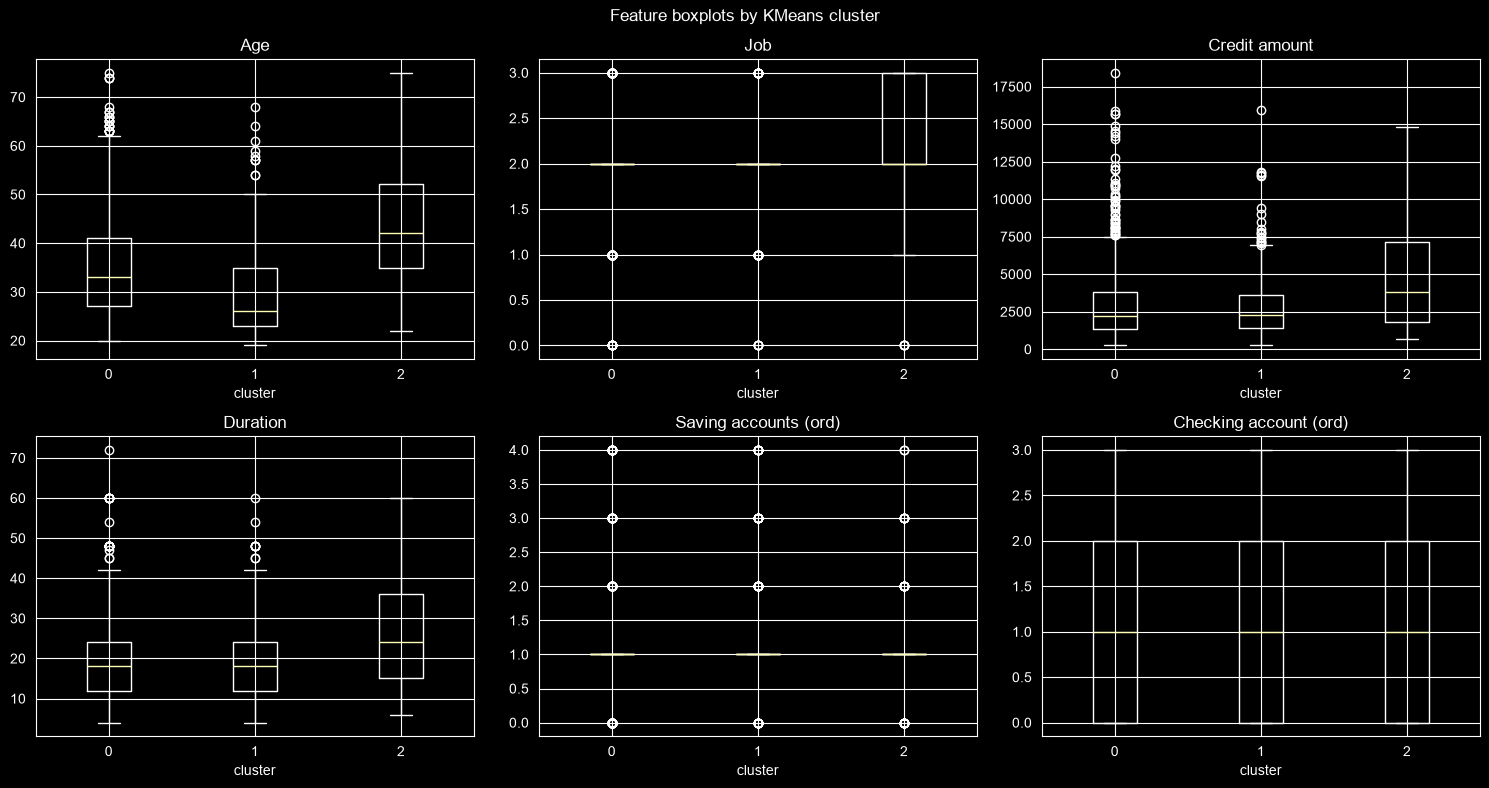

In [33]:
# Boxplots of numeric features grouped by KMeans cluster
box_cols = ['Age', 'Job', 'Credit amount', 'Duration',
            'Saving accounts (ord)', 'Checking account (ord)']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, box_cols):
    cluster_ids = sorted(df_result['kmeans'].unique())
    data_to_plot = [df_result.loc[df_result['kmeans'] == c, col] for c in cluster_ids]
    ax.boxplot(data_to_plot)
    ax.set_xticklabels([str(c) for c in cluster_ids])
    ax.set_title(col)
    ax.set_xlabel('cluster')
fig.suptitle('Feature boxplots by KMeans cluster')
fig.tight_layout()
plt.show()

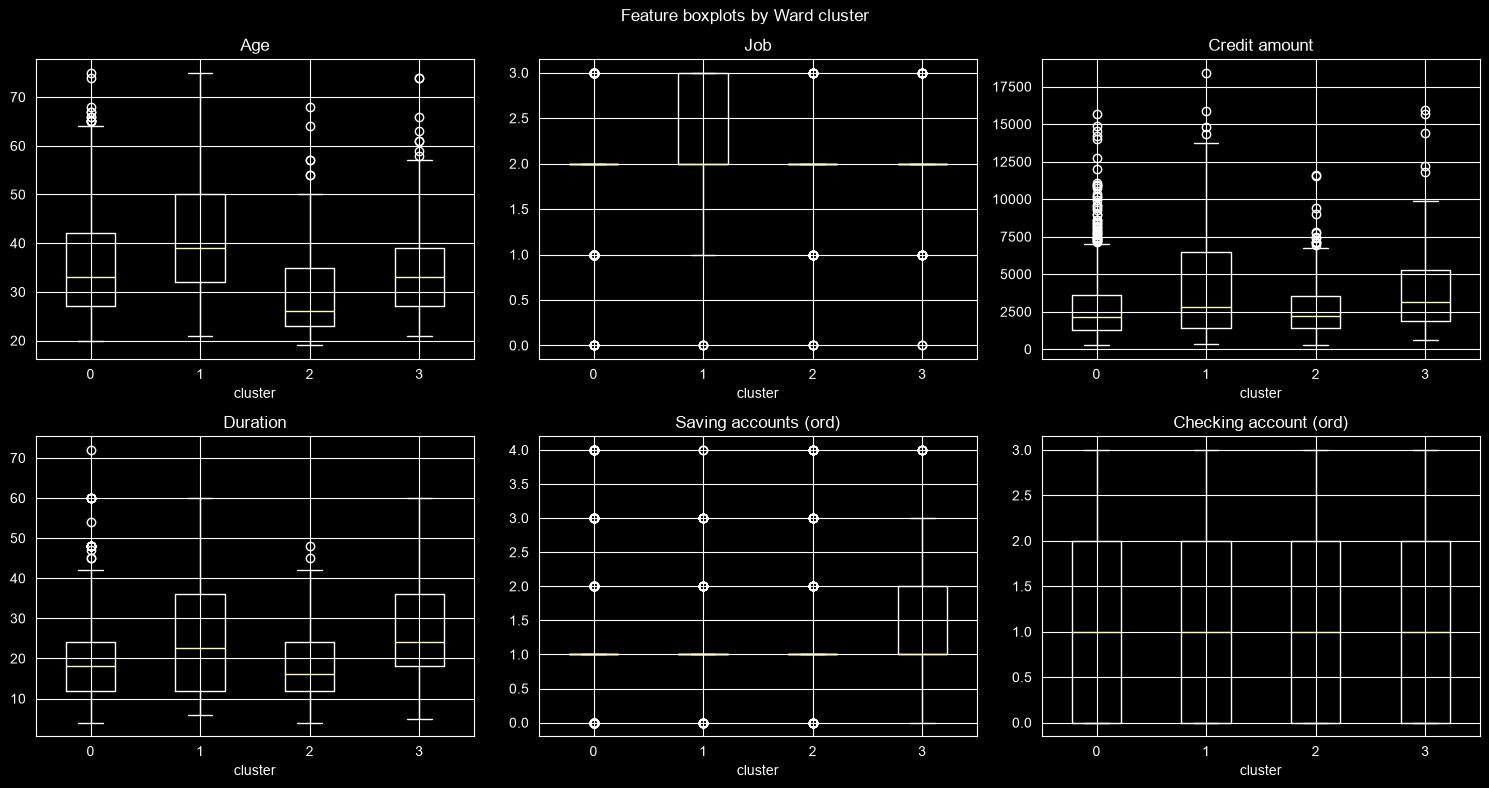

In [34]:
# The same boxplots for the Ward k=4 clusters

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, box_cols):
    cluster_ids = sorted(df_result['ward'].unique())
    data_to_plot = [df_result.loc[df_result['ward'] == c, col] for c in cluster_ids]
    ax.boxplot(data_to_plot)
    ax.set_xticklabels([str(c) for c in cluster_ids])
    ax.set_title(col)
    ax.set_xlabel('cluster')
fig.suptitle('Feature boxplots by Ward cluster')
fig.tight_layout()
plt.show()

# Both separation made by Age and Credit amount, Duration and Job plus Housing, Purpose and Sex
# Saving/Checking account levels are similar in clusters
# so the split follows housing, purpose, but not account wealth

In [37]:
print('\nMean feature values per Ward cluster (k=4):')
print(df_result.groupby('ward')[profile_cols].mean().round(2).to_string())

print('\nHousing share per Ward cluster, %:')
print((pd.crosstab(df_result['ward'], df_result['Housing'], normalize='index') * 100).round(1).to_string())

print('\nPurpose share per Ward cluster, % (top blocks):')
print((pd.crosstab(df_result['ward'], df_result['Purpose'], normalize='index') * 100).round(1).to_string())



Mean feature values per Ward cluster (k=4):
        Age   Job  Credit amount  Duration  Saving accounts (ord)  Checking account (ord)  Sex (bin)
ward                                                                                                
0     35.49  1.86        2928.66     19.83                   1.21                    0.96       0.72
1     41.39  2.11        4412.02     24.17                   0.99                    1.09       0.74
2     29.84  1.86        2914.40     17.96                   1.26                    0.97       0.45
3     35.48  1.91        4158.04     26.94                   1.30                    1.13       0.80

Housing share per Ward cluster, %:
Housing  free   own   rent
ward                      
0         0.5  98.8    0.7
1        65.8  27.6    6.6
2         0.0   0.0  100.0
3         5.2  78.4   16.5

Purpose share per Ward cluster, % (top blocks):
Purpose  business   car  domestic appliances  education  furniture/equipment  radio/TV  repairs  vacat

In [38]:
print('\nMean feature values per DBSCAN cluster:')
print(df_result.groupby('dbscan')[profile_cols].mean().round(2).to_string())

print('\nPurpose share per DBSCAN cluster, %:')
print((pd.crosstab(df_result['dbscan'], df_result['Purpose'], normalize='index') * 100).round(1).to_string())

print('\nDBSCAN mini clusters 1-3 turned out to be pure rare loan purposes')
print('(domestic appliances, repairs, vacation/others), cluster 0 is dense main trend.')


Mean feature values per DBSCAN cluster:
          Age   Job  Credit amount  Duration  Saving accounts (ord)  Checking account (ord)  Sex (bin)
dbscan                                                                                                
0       35.44  1.91        3243.97     20.85                   1.19                    0.99       0.69
1       34.25  1.75        1498.00     16.83                   1.17                    1.00       0.50
2       38.55  1.50        2728.09     19.09                   1.41                    1.05       0.77
3       39.92  2.50        8209.33     32.33                   1.00                    1.50       0.75

Purpose share per DBSCAN cluster, %:
Purpose  business   car  domestic appliances  education  furniture/equipment  radio/TV  repairs  vacation/others
dbscan                                                                                                          
0            10.2  35.3                  0.0        6.2                 19.0 

In [ ]:
#--------------------
# 10. Results log and conclusions
#--------------------

log_rows = [
    {'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
     'model': 'KMeans',
     'hyperparameters': f'k={KM_K}, n_init=10, random_state={RANDOM_STATE}',
     'n_clusters': KM_K, 'noise_share': 0.0,
     'silhouette': round(silhouette_score(X_scaled, labels_km), 4)},
    {'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
     'model': 'Hierarchical (ward)',
     'hyperparameters': f'k={HC_K}, linkage=ward',
     'n_clusters': HC_K, 'noise_share': 0.0,
     'silhouette': round(silhouette_score(X_scaled, labels_hc), 4)},
    {'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
     'model': 'DBSCAN',
     'hyperparameters': f'eps={DB_EPS:.4f}, min_samples={DB_MIN_SAMPLES}',
     'n_clusters': n_clusters_db, 'noise_share': round(noise_share_db, 4),
     'silhouette': round(sil_db, 4)},
]

log_path = os.path.join(output_dir, 'model_results.csv')
pd.DataFrame(log_rows).to_csv(log_path, mode='a', header=not os.path.exists(log_path), index=False)

results_df = pd.read_csv(log_path)
results_df = results_df.drop_duplicates(subset=['model'], keep='last').reset_index(drop=True)
print(results_df.to_string(index=False))


In [39]:
#--------------------
# Conclusion
#--------------------
# 1. Все фичи преобразованы в числовой вид. Пол в 0/1, housing and Purpose в OHE,
#   для Credit amount - log1p и StandardScaler.

# 2. KMeans, k=3 silhouette 0.1855: разбиение по housing

# 3. Hierarchical Ward, k=4 silhouette 0.1725: фича housing и назначение кредита (purpose):

# 4. DBSCAN eps=5.5115 по кванлилю 0.99, min_samples=10,
#    silhouette 0.3846, noise 0.0000 (кластеры получились разбалансированные - огромный кластер на 954 юзера и 3 совсем маленьких группы по назначению кредитов). значение 0.3846 видимо от этих мини груп.

# 5. Проецирование на 2д - PCA для 18 мерного сета не очень точно - около 1/4 данных попадает в маркировку
#   t-SNE и UMAP повторяют форму от результатов DBSCAN.

# 6. Что получилось по контексту данных:
#   более молодые клиенты (средн 30лет) с короткими кредитами. клиенты постарше (средн 44лет) с длинными кредитами, но не платят за жилье (которые free housing). В общем к конкретном случае кластеризация через k-means или ward выглядит более практичными чем DBSCAN.

# 7. сами методы кластеризации очень классный инструмент. если покопаться можно найти инсайты для бизнеса. И Похоже, что надо сравнивать несколько методов. иначе не  понятно то ли сам датасет такой, то ли криво подобраны параметры. Упражнение отличное!